# Этап 3. RSS-фильтр на нижнем уровне: пилот β = 1 и β = 2

Код: `rssrl/shield.py` (фильтр), `rssrl/scenarios.py` (сцена и момент нарушения), `rssrl/logger.py` (временные ряды), `rssrl/responsibility.py` (ответственность). Проверки: `tests/test_shield.py`, `tests/test_dynamics.py`, `tests/test_responsibility.py`.

**Пилот без PPO**: агент всегда выбирает IDLE — держит полосу и целевую скорость 25 м/с, на машину впереди сам не реагирует. Вся безопасность — только от фильтра.

**Сцена**: highway-v0, 50 фоновых машин (торможение ≤ 5 м/с²), 40 с. Нарушение — по расписанию: момент и машина берутся из эталонного прогона (IDLE + фильтр ρ: первый момент после 3 с, когда агент идет за машиной с зазором ≤ 1,1·d_min леммы 2) и одинаковы для всех вариантов агента. Нарушитель набирает торможение β·5 м/с² (с рывком ≤ 10 м/с³), тормозит до остановки и стоит.

**Динамика**: у всех машин ускорение меняется не быстрее J_max = 10 м/с³. Фильтр тормозит не слабее 4 м/с², а если по прогнозу 4 м/с² не хватает — экстренно, с физическим пределом 8 м/с². **d_min фильтра — лемма 2 с учетом рывка** (`rssrl/rss.py`): к пути задней машины добавлено время перехода от разгона +3 м/с² к торможению −4 м/с² с рывком 10 м/с³ (0,7 с). Сравнение с d_min как в статье — в ноутбуке 07.

**Варианты агента** (все на одних и тех же 20 сценах):
- фильтр с задержкой реакции ρ = 0,5 с — основной режим (предположение леммы 2);
- фильтр без задержки (мгновенный) — дополнительный вариант;
- без фильтра.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, plot_episode
from rssrl.responsibility import responsibility_table
from rssrl.rss import DEFAULT

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_03'  # все графики столкновений, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(20)
# основной режим — фильтр с задержкой ρ, дополнительный — мгновенный фильтр
VARIANTS = [(True, 0.5), (True, 0.0), (False, 0.5)]
NAMES = {(True, 0.5): 'фильтр, задержка ρ (основной)', (True, 0.0): 'фильтр, задержка 0 (доп.)',
         (False, 0.5): 'без фильтра'}

In [2]:
outcomes, logs = run_grid(SEEDS, [1.0, 2.0], VARIANTS, trigger='schedule')
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]
# доля шагов в каждом режиме фильтра
for mode in ['brake', 'emergency']:
    outcomes[f'доля_{mode}'] = [(log['shield_mode'] == mode).mean() for log in logs.values()]
outcomes.drop(columns=['crash_partners']).to_csv(PILOT / 'outcomes.csv', index=False)
table = outcomes.pivot_table(index='вариант', columns='beta', values='collision', aggfunc='sum')
table.columns = [f'β = {b:g}' for b in table.columns]
table = table.loc[list(NAMES.values())]
print('Число эпизодов со столкновением из 20:')
table

Число эпизодов со столкновением из 20:


,β = 1,β = 2
вариант,,
"фильтр, задержка ρ (основной)",0,0
"фильтр, задержка 0 (доп.)",0,0
без фильтра,19,19


In [3]:
summary = outcomes.groupby(['вариант', 'beta'], sort=False).agg(
    столкновений=('collision', 'sum'),
    из_них_с_нарушителем=('hit_violator', 'sum'),
    скорость_удара_медиана=('v_impact', 'median'),
    нарушение_было=('triggered', 'sum'),
    доля_шагов_торможение_4=('доля_brake', 'mean'),
    доля_шагов_экстренно_8=('доля_emergency', 'mean'),
    пробег_км=('distance_km', 'mean'),
).round(3)
summary

,,столкновений,из_них_с_нарушителем,скорость_удара_медиана,нарушение_было,доля_шагов_торможение_4,доля_шагов_экстренно_8,пробег_км
вариант,beta,,,,,,,
"фильтр, задержка ρ (основной)",1.0,0,0,NaN,20,0.651,0.011,0.442
"фильтр, задержка 0 (доп.)",1.0,0,0,NaN,20,0.564,0.010,0.441
без фильтра,1.0,19,15,25.0,17,0.000,0.000,0.432
"фильтр, задержка ρ (основной)",2.0,0,0,NaN,20,0.665,0.011,0.427
"фильтр, задержка 0 (доп.)",2.0,0,0,NaN,20,0.616,0.009,0.426
без фильтра,2.0,19,15,25.0,17,0.000,0.000,0.422


Что видно:
- **Без фильтра** агент врезается почти всегда, на полной скорости 25 м/с (IDLE не тормозит сам), и при β = 1 тоже; в 3 сценах из 20 он врезается еще до момента нарушения.
- **С фильтром** (d_min с учетом рывка) — 0 столкновений из 20 и при β = 1, и при β = 2, при обеих задержках. При β = 1 это критерий готовности: допущение RSS соблюдается, и агент с правильной реакцией не должен попадать в аварии.
- **Экстренный режим** почти не нужен (около 1 % шагов): новая d_min заранее оставляет место на время набора торможения. Большую долю шагов фильтр командует торможение 4 м/с², потому что агент стоит за остановившимся нарушителем, а IDLE все время просит разгон.
- Для сравнения: с d_min леммы 2 как в статье было 16 и 17 столкновений из 20 при задержке ρ — медленные въезды в стоящего нарушителя (см. ноутбук 07, где обе формулы идут рядом на 50 сценах).

## Ответственность за столкновения

По формализации RSS (`rssrl/responsibility.py`): момент опасности — начало последнего опасного отрезка с партнером перед ударом. Нарушитель отвечает, если тормозил сильнее 5 м/с²; агент — если не начал торможение ≥ 4 м/с² за ρ после момента опасности или отпустил его до удара. «Не установлено» — правила RSS не нарушил никто, а столкновение было.

In [4]:
resp = responsibility_table(outcomes, logs)
resp['вариант'] = [NAMES[(s, d)] for s, d in zip(resp['shield'], resp['reaction_delay'])]
resp.to_csv(PILOT / 'responsibility.csv', index=False)
(resp.pivot_table(index=['вариант', 'level'], columns='responsible', values='seed',
                  aggfunc='size', fill_value=0, sort=False)
     .rename_axis(index=['вариант', 'β'], columns='отвечает'))

отвечает         агент  оба
вариант     β              
без фильтра 1.0     19    0
            2.0      4   15

In [5]:
# время реакции агента (от момента опасности до команды торможения ≥ 4 м/с²)
resp.groupby(['вариант', 'level'], sort=False)['reaction_time'].describe()[['count', 'min', 'max']].round(2)

count  min  max
вариант     level                 
без фильтра 1.0      0.0  NaN  NaN
            2.0      0.0  NaN  NaN

## Механизм столкновений с фильтром

Для каждого столкновения с фильтром: скорость агента в момент удара и стоял ли агент (скорость < 0,5 м/с) после начала нарушения, но до удара. «Стоял, потом врезался» значит: агент уже остановился за стоящим нарушителем, фильтр отпустил тормоз, IDLE снова поехал, и торможение не успело набраться. Так было с d_min леммы 2 как в статье (при нулевых скоростях она всего 0,66 м). С d_min с учетом рывка (1,75 м при нулевых скоростях) столкновений с фильтром нет, и таблица пустая.

In [6]:
rows = []
for o in outcomes[outcomes.collision & outcomes.shield].itertuples():
    log = logs[(o.seed, o.beta, o.shield, o.reaction_delay)]
    i = log.index[log.crashed].min()
    after = log.loc[:i - 1]
    after = after[after['vio_v'].notna()]
    rows.append({'вариант': o.вариант, 'β': o.beta, 'seed': o.seed,
                 'скорость удара, м/с': o.v_impact,
                 'стоял до удара': bool((after['ego_v'] < 0.5).any()),
                 'режим фильтра перед ударом': log.loc[i - 1, 'shield_mode']})
mech = pd.DataFrame(rows, columns=['вариант', 'β', 'seed', 'скорость удара, м/с',
                                   'стоял до удара', 'режим фильтра перед ударом'])
mech.groupby(['вариант', 'β'], sort=False).agg(
    столкновений=('seed', 'size'),
    стоял_до_удара=('стоял до удара', 'sum'),
    скорость_удара_медиана=('скорость удара, м/с', 'median'),
    скорость_удара_макс=('скорость удара, м/с', 'max'),
).round(2)

,,столкновений,стоял_до_удара,скорость_удара_медиана,скорость_удара_макс
вариант,β,,,,


## Одна сцена, два β (общие сцены)

До момента нарушения прогоны с β = 1 и β = 2 совпадают полностью: сцена одна и та же. Разница появляется только после того, как лидер начинает тормозить.

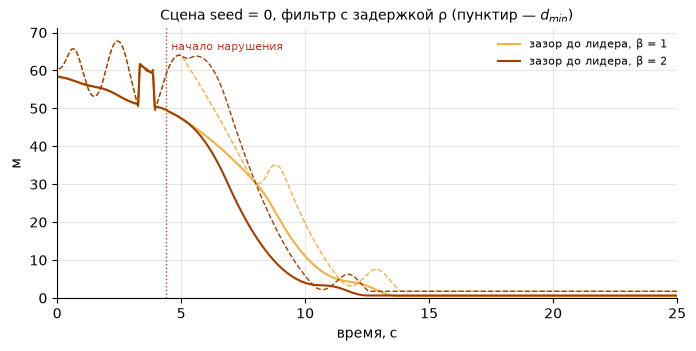

In [7]:
sub = outcomes[outcomes.shield & (outcomes.reaction_delay == 0.5)].pivot(index='seed', columns='beta', values='collision')
cand = sub.index[(~sub[1.0].astype(bool)) & sub[2.0].astype(bool)]
seed = int(cand[0]) if len(cand) else int(sub.index[0])
fig, ax = plt.subplots(figsize=(8, 3.5))
for beta, color in [(1.0, '#f5b041'), (2.0, '#a04000')]:
    log = logs[(seed, beta, True, 0.5)]
    ax.plot(log['t'], log['vio_gap'].fillna(log['gap']).clip(lower=0), color=color,
            label=f'зазор до лидера, β = {beta:g}')
    ax.plot(log['t'], log['d_min'], color=color, linewidth=1, linestyle='--')
t0 = logs[(seed, 1.0, True, 0.5)]['vio_v'].first_valid_index() / 15
ax.axvline(t0, color='#c0392b', linewidth=1, linestyle=':')
ax.text(t0 + 0.2, ax.get_ylim()[1] * 0.92, 'начало нарушения', fontsize=8, color='#c0392b')
ax.set_xlim(0, min(25, logs[(seed, 1.0, True, 0.5)]['t'].max()))
ax.set_ylim(bottom=0)
ax.set_xlabel('время, с'); ax.set_ylabel('м')
ax.set_title(f'Сцена seed = {seed}, фильтр с задержкой ρ (пунктир — $d_{{min}}$)', fontsize=10)
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
fig.savefig(FIG / '03_same_scene_two_betas.png', dpi=150, bbox_inches='tight')
plt.show()

## Временные ряды столкновений с фильтром

Для каждого столкновения: зазор и d_min, скорости, ускорения (команда политики, фактическое ускорение агента и нарушителя). Серым показаны шаги, где фильтр тормозит. Графики всех столкновений, включая варианты без фильтра, сохраняются в `results/pilot_03/`. Ниже — первые 4 при задержке ρ и все при задержке 0 (если с фильтром столкновений нет — пример без фильтра).

In [8]:
crashes = outcomes[outcomes.collision].sort_values(['shield', 'reaction_delay', 'beta', 'seed'],
                                                  ascending=[False, False, True, True])
for _, o in crashes.iterrows():
    key = (o.seed, o.beta, o.shield, o.reaction_delay)
    fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
    plot_episode(logs[key], f"{o['вариант']}, β = {o.beta:g}, seed = {o.seed}", axes)
    name = f"{'shield' if o.shield else 'noshield'}_d{o.reaction_delay:g}_b{o.beta:g}_s{o.seed}.png"
    fig.savefig(PILOT / name, dpi=110, bbox_inches='tight')
    plt.close(fig)
print('сохранено графиков:', len(crashes))

сохранено графиков: 38


С фильтром столкновений нет. Пример столкновения без фильтра:


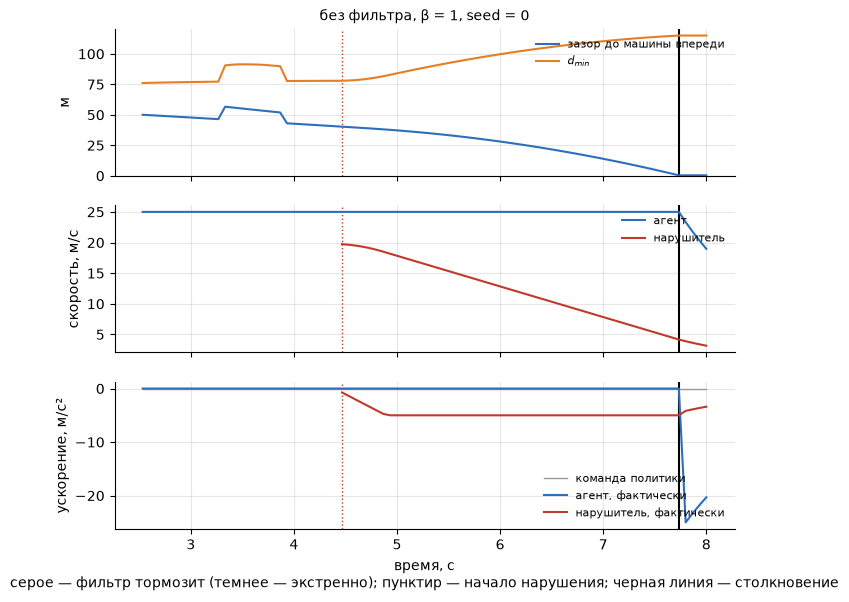

In [9]:
show = pd.concat([
    crashes[(crashes.shield) & (crashes.reaction_delay == 0.5)].head(4),
    crashes[(crashes.shield) & (crashes.reaction_delay == 0)],
])
if show.empty:  # с фильтром столкновений нет — показываем пример без фильтра
    print('С фильтром столкновений нет. Пример столкновения без фильтра:')
    show = crashes[~crashes.shield].head(1)
for i, (_, o) in enumerate(show.iterrows()):
    key = (o.seed, o.beta, o.shield, o.reaction_delay)
    log = logs[key]
    t0 = log.loc[log['vio_v'].notna(), 't'].min()
    part = log[(log.t >= t0 - 2) & (log.t <= log.t.max())]
    fig, axes = plt.subplots(3, 1, figsize=(8, 6.5), sharex=True)
    plot_episode(part, f"{o['вариант']}, β = {o.beta:g}, seed = {o.seed}", axes)
    if i == 0:
        fig.savefig(FIG / '03_collision_example.png', dpi=150, bbox_inches='tight')
    plt.show()

## Вывод пилота

1. Рывок для торможения фильтра — экстренный, 10 м/с³ (один предел для всех машин, `rssrl/dynamics.py`); комфортный рывок нигде не используется.
2. Причиной прежних аварий при β = 1 была формула: лемма 2 как в статье не учитывает 0,7 с набора торможения с рывком. С d_min, где этот путь учтен, при β = 1 и задержке ρ столкновений нет (20 сцен здесь, 12 сцен в тесте `test_no_collisions_with_jerk_and_jerk_aware_dmin`), в номинальном режиме — тоже (ноутбук 05). Критерий готовности выполнен.
3. При β = 2 на этих 20 сценах столкновений тоже нет: большая дистанция и экстренное торможение 8 м/с² покрывают торможение лидера 10 м/с². Как частота растет с β на 50 сценах — в ноутбуке 07.
4. Нарушение здесь — по расписанию (одинаковый момент для всех вариантов): с новой формулой осторожный мгновенный фильтр никогда не подходит на 1,1·d_min, и нарушение «по зазору» у него не наступало бы вовсе.